## CE2 Phase 10: Unsupervised Learning - PCA and Clustering

### 1. Unsupervised Learning Paradigm
Unlike supervised regression and classification, **unsupervised learning** discovers intrinsic geometric structures, continuous manifolds, and latent groupings within the feature space without reference to ground-truth target labels ($y$). In this phase:
- Target labels (`age` / life-stage cohorts) are **never used during model fitting**.
- Chronological age is consulted **strictly post-hoc** as an external benchmark to evaluate whether unsupervised geometric clusters naturally correspond to biological age progression.

---

### 2. Feature Selection: Why Exclude Demographic Dummies?
Clustering is performed **exclusively on the 7 standardized continuous facial geometry features**:
- The one-hot encoded demographic features (`gender_0`, `gender_1`, `race_0`–`race_4`) are discrete binary indicators ($0$ or $1$).
- In standard Euclidean distance calculations, discrete binary coordinates dominate continuous normalized distances, causing clustering algorithms to trivially recover demographic subgroups rather than discovering genuine variations in facial morphology.
- Restricting input features to normalized continuous facial measurements ensures that clusters reflect purely morphological and structural variations.

---

### 3. Dimensionality Reduction & Clustering Algorithms
1. **Principal Component Analysis (PCA):** An orthogonal linear transformation that projects correlated facial features into an ordered set of mutually uncorrelated axes (Principal Components), ranked by explained variance.
2. **$K$-Means Clustering:** A partition-based centroid algorithm that iteratively minimizes within-cluster sum of squares (inertia): $\sum_{k} \sum_{x \in C_k} ||x - \mu_k||^2$.
3. **Hierarchical Agglomerative Clustering (Ward's Linkage):** A bottom-up tree-based clustering method that merges clusters hierarchically to minimize the incremental increase in total within-cluster variance.
4. **DBSCAN (Density-Based Spatial Clustering of Applications with Noise):** A non-parametric density-based method that discovers arbitrarily shaped clusters by connecting core points with high local point density ($\text{min\_samples}$ within radius $\epsilon$) while explicitly isolating sparse points as noise (label $-1$).

---

### 4. Cluster Validation & External Alignment Metrics
* **Silhouette Coefficient ($s$):**
  $$s_i = \frac{b_i - a_i}{\max(a_i, b_i)}$$
  where $a_i$ is the mean intra-cluster distance for point $i$, and $b_i$ is the mean distance to the nearest neighboring cluster.
  - Bounded in $[-1, +1]$: values near $+1$ indicate dense, well-separated clusters; $0$ denotes overlapping clusters; negative values signify probable misassignment.
* **Adjusted Rand Index (ARI):** Measures the similarity between unsupervised cluster assignments and the 5 true life-stage cohorts, adjusted for chance agreement ($	ext{ARI} = 0$ for random chance, $+1$ for perfect agreement).
* **Normalized Mutual Information (NMI):** Quantifies the mutual information shared between cluster labels and ground-truth age groups, normalized between $0$ (no shared information) and $1$ (perfect correlation).


In [1]:
import os
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
    adjusted_rand_score, normalized_mutual_info_score)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold, cross_val_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Ensure relative paths work from project root
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Load full processed dataset (2998 rows)
X_features = pd.read_csv("data/processed/X_features.csv")
y_target = pd.read_csv("data/processed/y_target.csv")["age"]

# Define 7 continuous geometry features
continuous_cols = [
    'eye_distance', 'mouth_width', 'face_width', 'face_height',
    'face_aspect_ratio', 'eye_to_face_ratio', 'mouth_to_face_ratio'
]

# Standardize continuous features (mean=0, std=1)
X_cont = X_features[continuous_cols]
scaler = StandardScaler()
Z = scaler.fit_transform(X_cont)

# Create 5 ground-truth life-stage cohorts for post-hoc validation only
bins = [0, 12, 19, 39, 59, 200]
class_names = ["0-12", "13-19", "20-39", "40-59", "60+"]
age_group = pd.cut(y_target, bins=bins, labels=False).astype(int)

print(f"Dataset shape: X_features = {X_features.shape}, y_target = {y_target.shape}")
print(f"Continuous standardized feature matrix Z shape: {Z.shape}")
print("\nGround-truth life-stage cohort counts (used only for post-hoc validation):")
for idx, name in enumerate(class_names):
    count = np.sum(age_group == idx)
    print(f"  Cohort {idx} ({name:5s}): {count:4d} instances ({count/len(y_target)*100:5.2f}%)")


Dataset shape: X_features = (2998, 14), y_target = (2998,)
Continuous standardized feature matrix Z shape: (2998, 7)

Ground-truth life-stage cohort counts (used only for post-hoc validation):
  Cohort 0 (0-12 ):  450 instances (15.01%)
  Cohort 1 (13-19):  153 instances ( 5.10%)
  Cohort 2 (20-39): 1457 instances (48.60%)
  Cohort 3 (40-59):  591 instances (19.71%)
  Cohort 4 (60+  ):  347 instances (11.57%)



PCA Explained Variance Summary:
Component  Explained_Variance_Ratio  Cumulative_Variance_Ratio
      PC1                    0.4926                     0.4926
      PC2                    0.3625                     0.8551
      PC3                    0.1121                     0.9672
      PC4                    0.0320                     0.9992
      PC5                    0.0005                     0.9997
      PC6                    0.0003                     1.0000
      PC7                    0.0000                     1.0000

Components required to reach >= 90% cumulative variance: 3 components (96.72%)
Components required to reach >= 95% cumulative variance: 3 components (96.72%)

Principal Component Loadings (Eigenvectors):
     eye_distance  mouth_width  face_width  face_height  face_aspect_ratio  eye_to_face_ratio  mouth_to_face_ratio
PC1        0.4391       0.5113      0.1391       0.3601             0.0547             0.4350               0.4522
PC2       -0.3417      -0.116

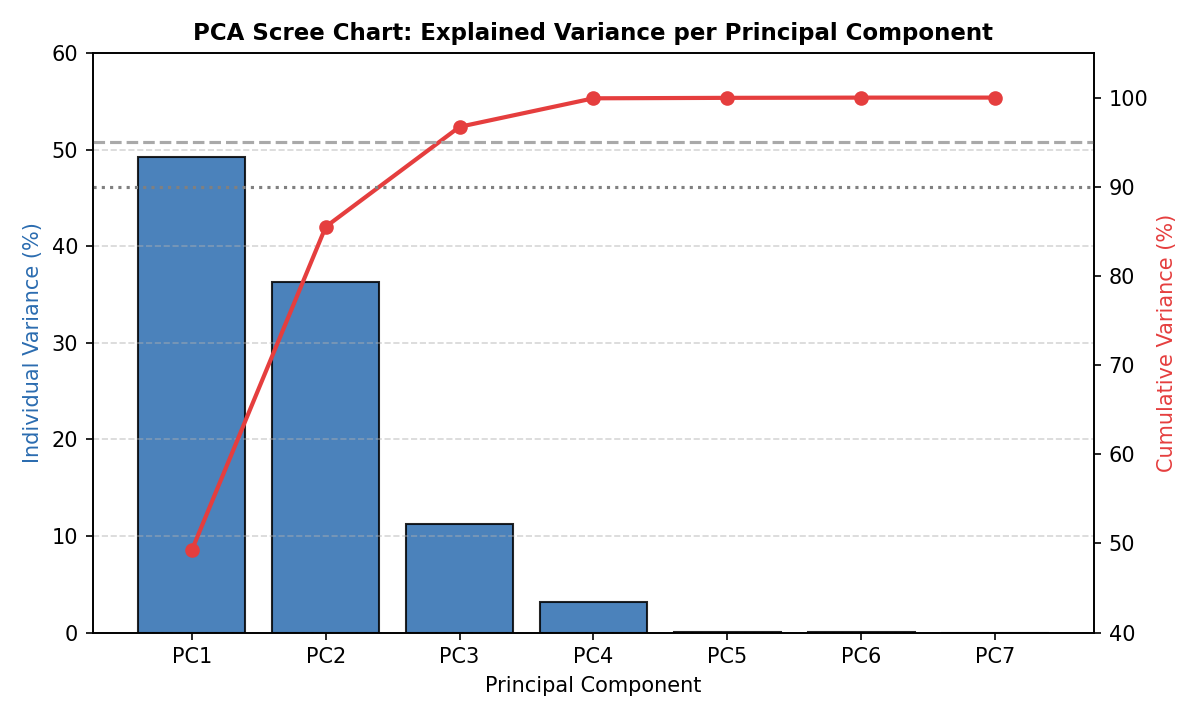

In [2]:
# Fit PCA on standardized continuous features
pca = PCA().fit(Z)
exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

# Tabulate variance explained per principal component
df_pca_var = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Explained_Variance_Ratio": exp_var,
    "Cumulative_Variance_Ratio": cum_var
})

print("PCA Explained Variance Summary:")
print(df_pca_var.round(4).to_string(index=False))

# Identify number of components required for variance thresholds
n_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)
print(f"\nComponents required to reach >= 90% cumulative variance: {n_90} components ({cum_var[n_90-1]*100:.2f}%)")
print(f"Components required to reach >= 95% cumulative variance: {n_95} components ({cum_var[n_95-1]*100:.2f}%)")

# Principal Component Loadings DataFrame
df_loadings = pd.DataFrame(
    pca.components_,
    index=[f"PC{i+1}" for i in range(len(exp_var))],
    columns=continuous_cols
)

print("\nPrincipal Component Loadings (Eigenvectors):")
print(df_loadings.round(4).to_string())

# Plot Scree Chart (Individual Variance Bars + Cumulative Variance Curve)
fig, ax1 = plt.subplots(figsize=(8, 4.8))

pc_indices = np.arange(1, len(exp_var) + 1)
bars = ax1.bar(pc_indices, exp_var * 100, color="#2b6cb0", alpha=0.85, edgecolor="black", label="Individual Variance Explained (%)")
ax1.set_xlabel("Principal Component", fontsize=10)
ax1.set_ylabel("Individual Variance (%)", color="#2b6cb0", fontsize=10)
ax1.set_xticks(pc_indices)
ax1.set_xticklabels([f"PC{i}" for i in pc_indices])
ax1.set_ylim(0, 60)
ax1.grid(True, linestyle="--", alpha=0.5, axis="y")

# Cumulative line on secondary y-axis
ax2 = ax1.twinx()
ax2.plot(pc_indices, cum_var * 100, marker='o', color="#e53e3e", linewidth=2, label="Cumulative Variance (%)")
ax2.axhline(90, color="gray", linestyle=":", label="90% Threshold")
ax2.axhline(95, color="darkgray", linestyle="--", label="95% Threshold")
ax2.set_ylabel("Cumulative Variance (%)", color="#e53e3e", fontsize=10)
ax2.set_ylim(40, 105)

plt.title("PCA Scree Chart: Explained Variance per Principal Component", fontsize=11, fontweight="bold")
plt.tight_layout()

plt.savefig("visualizations/21_pca_scree.png", dpi=150)
plt.show()


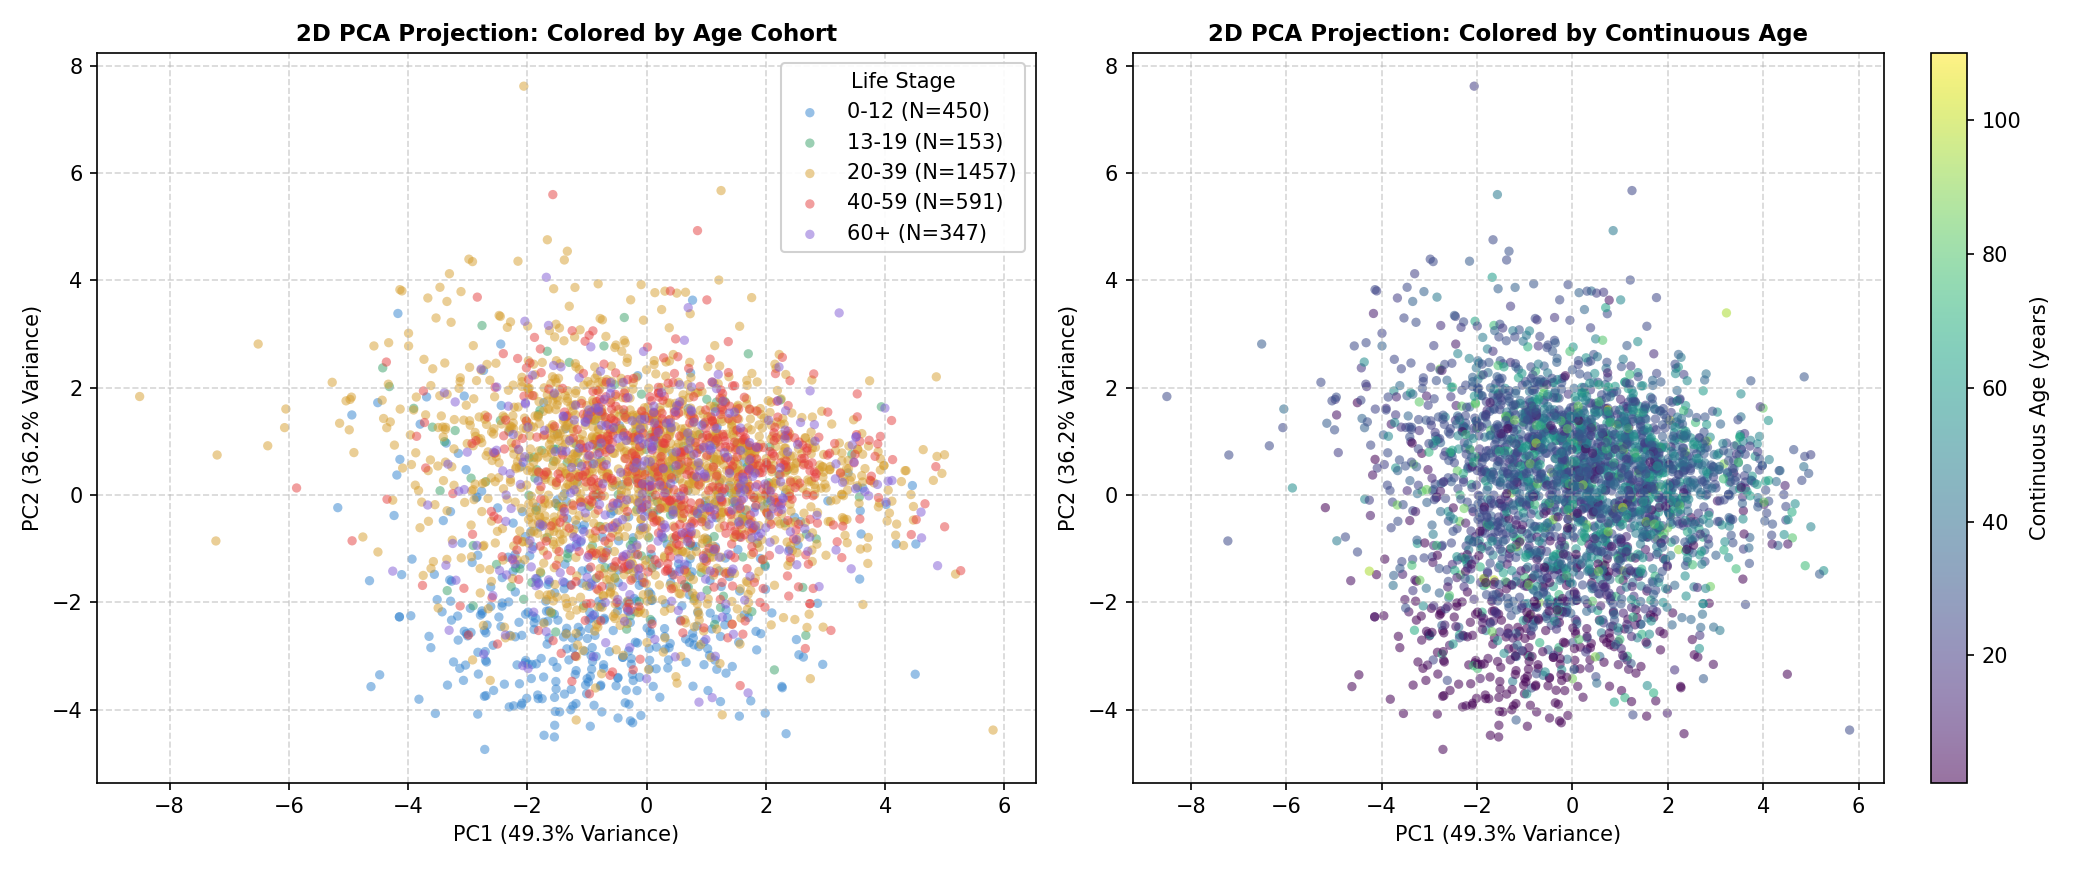

In [3]:
# Transform data onto the top 2 principal components
scores_2d = pca.transform(Z)[:, :2]
pc1_scores = scores_2d[:, 0]
pc2_scores = scores_2d[:, 1]

pc1_pct = exp_var[0] * 100
pc2_pct = exp_var[1] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))

# Left plot: Colored by discrete 5 life-stage age cohorts
cohort_colors = ["#3182ce", "#38a169", "#d69e2e", "#e53e3e", "#805ad5"]
for idx, name in enumerate(class_names):
    mask = (age_group == idx)
    axes[0].scatter(
        pc1_scores[mask], pc2_scores[mask],
        c=cohort_colors[idx], label=f"{name} (N={np.sum(mask)})",
        alpha=0.5, s=20, edgecolors="none"
    )

axes[0].set_title("2D PCA Projection: Colored by Age Cohort", fontsize=11, fontweight="bold")
axes[0].set_xlabel(f"PC1 ({pc1_pct:.1f}% Variance)", fontsize=10)
axes[0].set_ylabel(f"PC2 ({pc2_pct:.1f}% Variance)", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(frameon=True, facecolor="white", framealpha=0.9, title="Life Stage")

# Right plot: Colored by continuous age gradient
scatter = axes[1].scatter(
    pc1_scores, pc2_scores,
    c=y_target, cmap="viridis",
    alpha=0.55, s=20, edgecolors="none"
)
cbar = fig.colorbar(scatter, ax=axes[1])
cbar.set_label("Continuous Age (years)", fontsize=10)

axes[1].set_title("2D PCA Projection: Colored by Continuous Age", fontsize=11, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({pc1_pct:.1f}% Variance)", fontsize=10)
axes[1].set_ylabel(f"PC2 ({pc2_pct:.1f}% Variance)", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("visualizations/22_pca_projection.png", dpi=150)
plt.show()


In [4]:
# Supervised Check: Principal Component Regression (PCR) vs. Standard Multiple LR
# Note: Executed exclusively on TRAINING data using 5-fold cross-validation.
X_train = pd.read_csv("data/processed/X_train.csv")
y_train = pd.read_csv("data/processed/y_train.csv")["age"]
dummy_cols = ['gender_1', 'race_1', 'race_2', 'race_3', 'race_4']

# Drop reference categories (gender_0, race_0)
X_train = X_train.drop(columns=["gender_0", "race_0"])

cv_pcr = KFold(5, shuffle=True, random_state=42)

# Baseline: Multiple LR without PCA (StandardScaler on 7 continuous + passthrough dummies)
pipe_no_pca = Pipeline([
    ("prep", ColumnTransformer([
        ("scale", StandardScaler(), continuous_cols),
        ("dummies", "passthrough", dummy_cols)
    ])),
    ("reg", LinearRegression())
])
no_pca_scores = cross_val_score(pipe_no_pca, X_train, y_train, cv=cv_pcr, scoring="r2")
no_pca_mean = np.mean(no_pca_scores)
no_pca_std = np.std(no_pca_scores)

# PCR sweep across n_components from 1 to 7
pcr_rows = []
for n in range(1, 8):
    pipe_pca = Pipeline([
        ("prep", ColumnTransformer([
            ("pca", Pipeline([
                ("scale", StandardScaler()),
                ("p", PCA(n_components=n))
            ]), continuous_cols),
            ("dummies", "passthrough", dummy_cols)
        ])),
        ("reg", LinearRegression())
    ])
    scores_n = cross_val_score(pipe_pca, X_train, y_train, cv=cv_pcr, scoring="r2")
    pcr_rows.append({
        "n_components": n,
        "CV_R2_Mean": np.mean(scores_n),
        "CV_R2_Std": np.std(scores_n)
    })

df_pcr = pd.DataFrame(pcr_rows)
print(f"Reference Multiple LR (No PCA) 5-Fold CV R²: {no_pca_mean:.6f} +/- {no_pca_std:.6f}")
print("\nPrincipal Component Regression Performance (n_components = 1 to 7):")
print(df_pcr.round(6).to_string(index=False))

# Mathematical verification: Full PCA (n=7) is an exact orthogonal rotation
diff_n7 = abs(df_pcr.loc[df_pcr["n_components"] == 7, "CV_R2_Mean"].values[0] - no_pca_mean)
print(f"\nDiscrepancy between n=7 PCR and No-PCA Linear Regression: {diff_n7:.10f}")
if diff_n7 > 1e-6:
    print("WARNING: PCR at n=7 does not match unrotated Multiple Linear Regression within 1e-6!")
else:
    print("Verification Passed: n=7 PCR exactly reproduces full Multiple Linear Regression (orthogonal rotation identity).")


Reference Multiple LR (No PCA) 5-Fold CV R²: 0.163666 +/- 0.013852

Principal Component Regression Performance (n_components = 1 to 7):
 n_components  CV_R2_Mean  CV_R2_Std
            1    0.084024   0.010714
            2    0.144417   0.015898
            3    0.142703   0.014301
            4    0.142172   0.014395
            5    0.161663   0.011379
            6    0.162099   0.010530
            7    0.163666   0.013852

Discrepancy between n=7 PCR and No-PCA Linear Regression: 0.0000000000
Verification Passed: n=7 PCR exactly reproduces full Multiple Linear Regression (orthogonal rotation identity).



K-Means Parameter Sweep Results (k = 2 to 10):
 k      Inertia  Silhouette                                      Cluster_Sizes
 2 14338.698133    0.285102                                       [1522, 1476]
 3 10380.160126    0.309476                                   [992, 746, 1260]
 4  8872.110611    0.256277                               [722, 548, 798, 930]
 5  7774.542811    0.252694                          [646, 937, 435, 489, 491]
 6  7140.796814    0.231087                     [540, 426, 644, 618, 386, 384]
 7  6576.945779    0.224605                [354, 512, 703, 419, 431, 348, 231]
 8  6171.604735    0.213237           [320, 348, 524, 200, 468, 324, 570, 244]
 9  5813.611971    0.217144      [443, 329, 314, 334, 165, 441, 485, 279, 208]
10  5484.138589    0.211926 [224, 372, 370, 290, 240, 115, 427, 283, 423, 254]

Optimal K-Means cluster count: best_k_km = 3 (Silhouette Score = 0.3095)



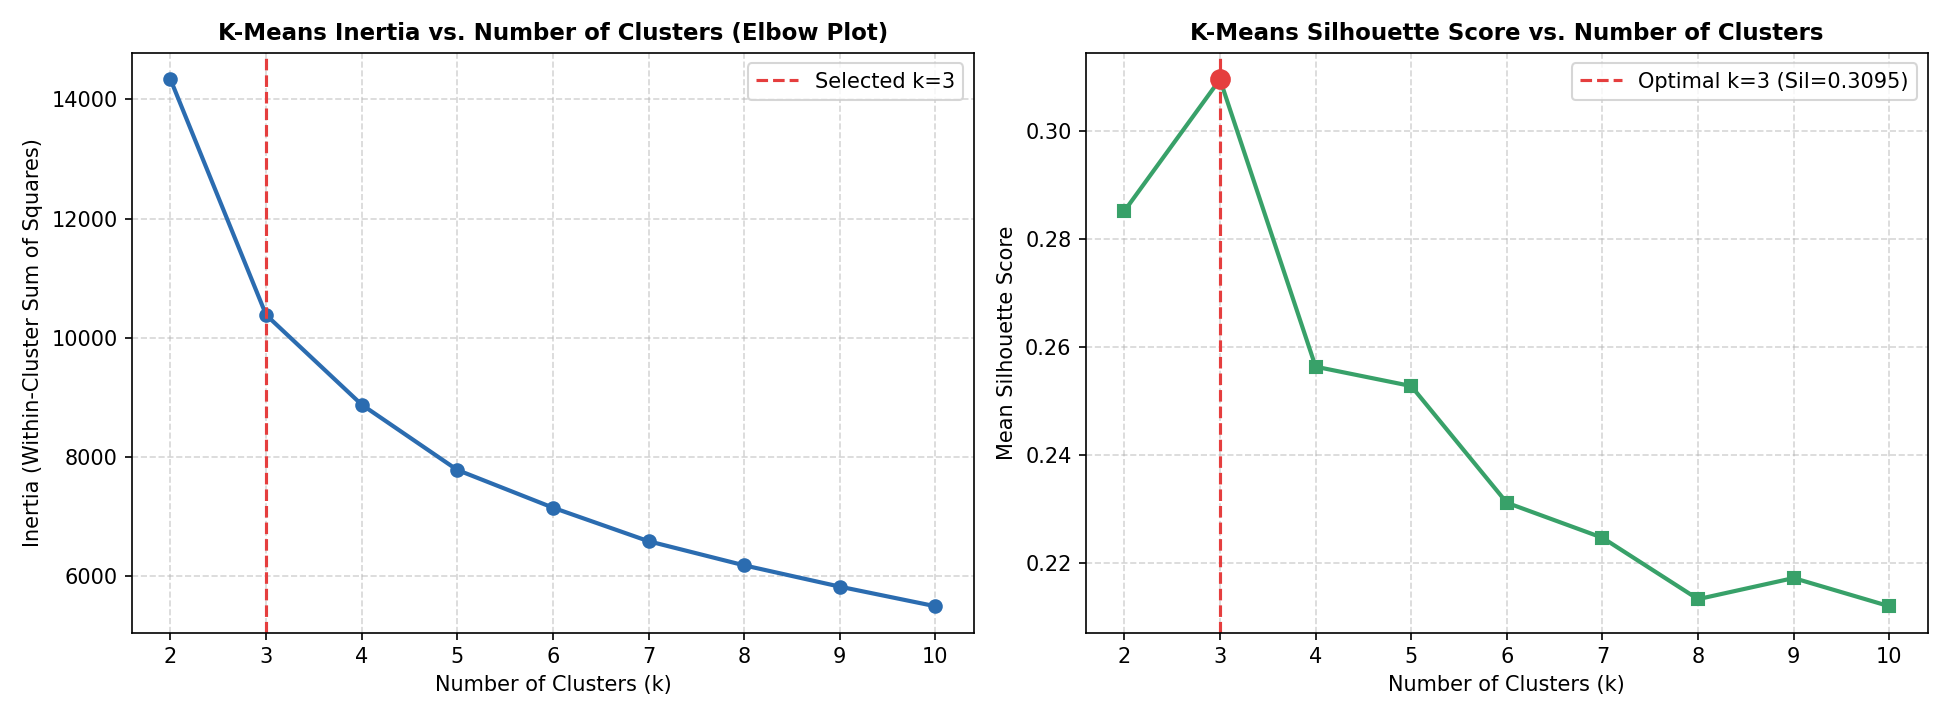

In [5]:
# K-Means Parameter Sweep across k = 2 to 10
km_sweep_rows = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertia = km.inertia_
    sil = silhouette_score(Z, km.labels_)
    cluster_sizes = np.bincount(km.labels_)
    
    km_sweep_rows.append({
        "k": k,
        "Inertia": inertia,
        "Silhouette": sil,
        "Cluster_Sizes": list(cluster_sizes)
    })

df_km_sweep = pd.DataFrame(km_sweep_rows)
print("K-Means Parameter Sweep Results (k = 2 to 10):")
print(df_km_sweep[["k", "Inertia", "Silhouette", "Cluster_Sizes"]].to_string(index=False))

# Select best k based on highest Silhouette Score
best_k_km = int(df_km_sweep.loc[df_km_sweep["Silhouette"].idxmax(), "k"])
best_km_sil = df_km_sweep["Silhouette"].max()
print(f"\nOptimal K-Means cluster count: best_k_km = {best_k_km} (Silhouette Score = {best_km_sil:.4f})")

# Plot Elbow Chart and Silhouette Score side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: Inertia vs k (Elbow curve)
axes[0].plot(df_km_sweep["k"], df_km_sweep["Inertia"], marker='o', color="#2b6cb0", linewidth=2)
axes[0].axvline(best_k_km, color="#e53e3e", linestyle="--", label=f"Selected k={best_k_km}")
axes[0].set_title("K-Means Inertia vs. Number of Clusters (Elbow Plot)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Number of Clusters (k)", fontsize=10)
axes[0].set_ylabel("Inertia (Within-Cluster Sum of Squares)", fontsize=10)
axes[0].set_xticks(range(2, 11))
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(frameon=True)

# Right: Silhouette Score vs k
axes[1].plot(df_km_sweep["k"], df_km_sweep["Silhouette"], marker='s', color="#38a169", linewidth=2)
axes[1].axvline(best_k_km, color="#e53e3e", linestyle="--", label=f"Optimal k={best_k_km} (Sil={best_km_sil:.4f})")
axes[1].scatter([best_k_km], [best_km_sil], color="#e53e3e", s=80, zorder=5)
axes[1].set_title("K-Means Silhouette Score vs. Number of Clusters", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Number of Clusters (k)", fontsize=10)
axes[1].set_ylabel("Mean Silhouette Score", fontsize=10)
axes[1].set_xticks(range(2, 11))
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig("visualizations/23_kmeans_selection.png", dpi=150)
plt.show()


Cluster Profile Summary for K-Means (k=3) on Raw Continuous Features:
  Cluster  Size   Pct  eye_distance  mouth_width  face_width  face_height  face_aspect_ratio  eye_to_face_ratio  mouth_to_face_ratio  Mean_Age  Median_Age
Cluster 0   992 33.09         72.10        59.42      157.68       190.75               1.21               0.46                 0.38     35.07        28.0
Cluster 1   746 24.88         79.82        63.34      180.63       191.25               1.06               0.44                 0.35     24.78        23.0
Cluster 2  1260 42.03         81.75        70.70      168.97       198.44               1.18               0.48                 0.42     37.23        34.0

Row-Normalized Crosstab: Cluster vs. Life-Stage Cohort (%):
            0-12  13-19  20-39  40-59    60+
Cluster 0   5.04   5.14  60.38  18.35  11.09
Cluster 1  41.82   4.96  29.89  12.73  10.59
Cluster 2   6.98   5.16  50.40  24.92  12.54

Alignment with Ground-Truth Age Cohorts:
  Adjusted Rand Index (ARI)

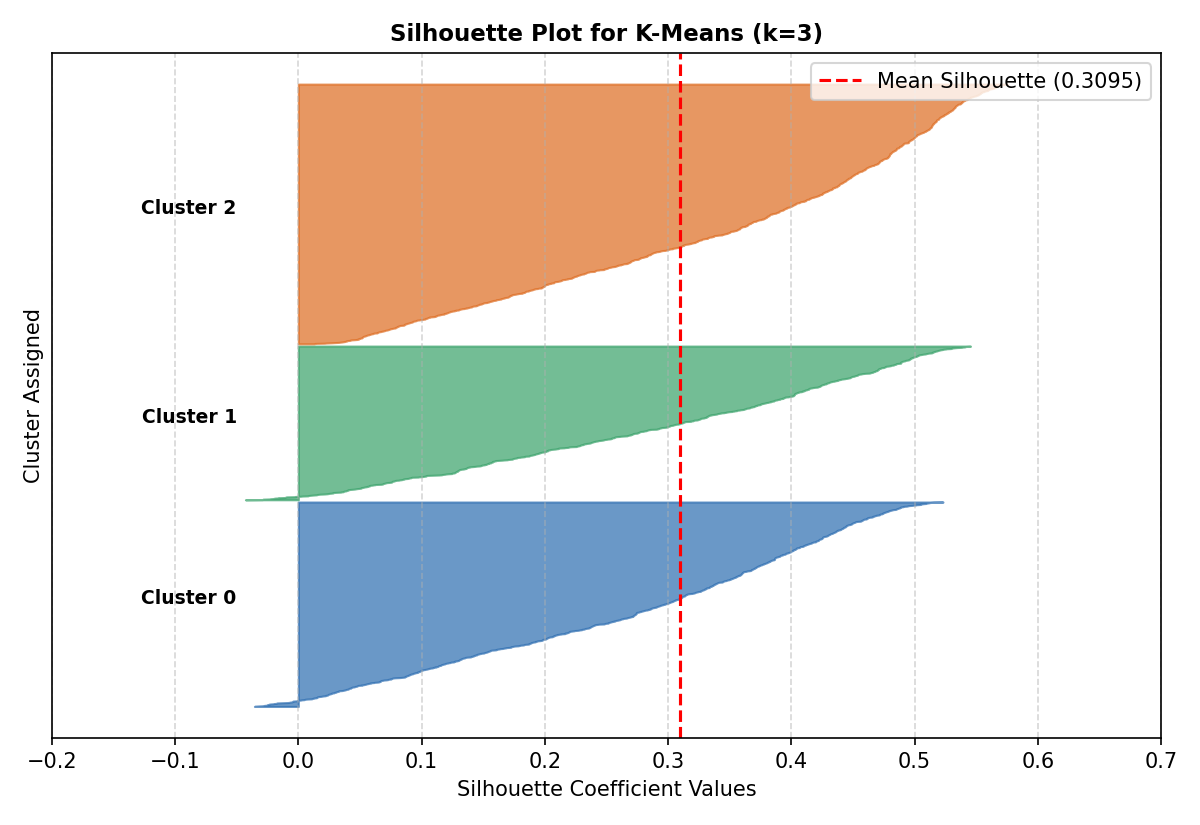

In [6]:
# Fit K-Means at optimal best_k_km
km_optimal = KMeans(n_clusters=best_k_km, n_init=10, random_state=42).fit(Z)
km_labels = km_optimal.labels_
mean_sil_km = silhouette_score(Z, km_labels)
sample_sil_values = silhouette_samples(Z, km_labels)

# 1. Per-Sample Silhouette Plot
fig, ax = plt.subplots(figsize=(8, 5.5))
y_lower = 10
cluster_colors = ["#2b6cb0", "#38a169", "#dd6b20", "#805ad5", "#e53e3e"]

for i in range(best_k_km):
    ith_cluster_sil = sample_sil_values[km_labels == i]
    ith_cluster_sil.sort()
    size_cluster_i = ith_cluster_sil.shape[0]
    y_upper = y_lower + size_cluster_i
    
    color = cluster_colors[i % len(cluster_colors)]
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil, facecolor=color, edgecolor=color, alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, f"Cluster {i}", fontsize=9, fontweight="bold", ha="right")
    y_lower = y_upper + 10

ax.axvline(x=mean_sil_km, color="red", linestyle="--", linewidth=1.5, label=f"Mean Silhouette ({mean_sil_km:.4f})")
ax.set_title(f"Silhouette Plot for K-Means (k={best_k_km})", fontsize=11, fontweight="bold")
ax.set_xlabel("Silhouette Coefficient Values", fontsize=10)
ax.set_ylabel("Cluster Assigned", fontsize=10)
ax.set_yticks([])
ax.set_xlim(-0.2, 0.7)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True, loc="upper right")
plt.tight_layout()

plt.savefig("visualizations/24_kmeans_silhouette.png", dpi=150)
plt.show()

# 2. Cluster Profile Table on RAW Unscaled Features
profile_rows = []
for c_idx in range(best_k_km):
    mask = (km_labels == c_idx)
    row_dict = {
        "Cluster": f"Cluster {c_idx}",
        "Size": int(np.sum(mask)),
        "Pct": np.sum(mask) / len(Z) * 100
    }
    for col in continuous_cols:
        row_dict[col] = X_features.loc[mask, col].mean()
    row_dict["Mean_Age"] = y_target[mask].mean()
    row_dict["Median_Age"] = y_target[mask].median()
    profile_rows.append(row_dict)

df_km_profile = pd.DataFrame(profile_rows)
print(f"Cluster Profile Summary for K-Means (k={best_k_km}) on Raw Continuous Features:")
print(df_km_profile.round(2).to_string(index=False))

# 3. Crosstab vs Age Group Cohorts
df_crosstab = pd.crosstab(
    km_labels,
    age_group,
    normalize="index"
) * 100.0
df_crosstab.columns = class_names
df_crosstab.index = [f"Cluster {i}" for i in range(best_k_km)]
print("\nRow-Normalized Crosstab: Cluster vs. Life-Stage Cohort (%):")
print(df_crosstab.round(2).to_string())

# 4. External Alignment Metrics
ari_km = adjusted_rand_score(age_group, km_labels)
nmi_km = normalized_mutual_info_score(age_group, km_labels)
print(f"\nAlignment with Ground-Truth Age Cohorts:")
print(f"  Adjusted Rand Index (ARI):             {ari_km:.4f}")
print(f"  Normalized Mutual Information (NMI):    {nmi_km:.4f}")


Hierarchical Agglomerative Clustering (Ward) Parameter Sweep:
 k  Silhouette
 2      0.2616
 3      0.2489
 4      0.1972
 5      0.1657
 6      0.1678
 7      0.1712
 8      0.1558
 9      0.1573
10      0.1415

Optimal Ward Hierarchical cluster count: best_k_hc = 2 (Silhouette Score = 0.2616)

Linkage Criterion Comparison at k = 3:
 Linkage  k  Silhouette    Cluster_Sizes
    ward  3      0.2489 [1684, 668, 646]
complete  3      0.2158 [663, 1655, 680]
 average  3      0.4234     [2989, 1, 8]
  single  3      0.5643     [2996, 1, 1]

Ward Model (k=2) Alignment with Ground-Truth Age Cohorts:
  Adjusted Rand Index (ARI):             0.0055
  Normalized Mutual Information (NMI):    0.0098

Cross-Algorithm Agreement (ARI between K-Means and Ward at k=3): 0.4331



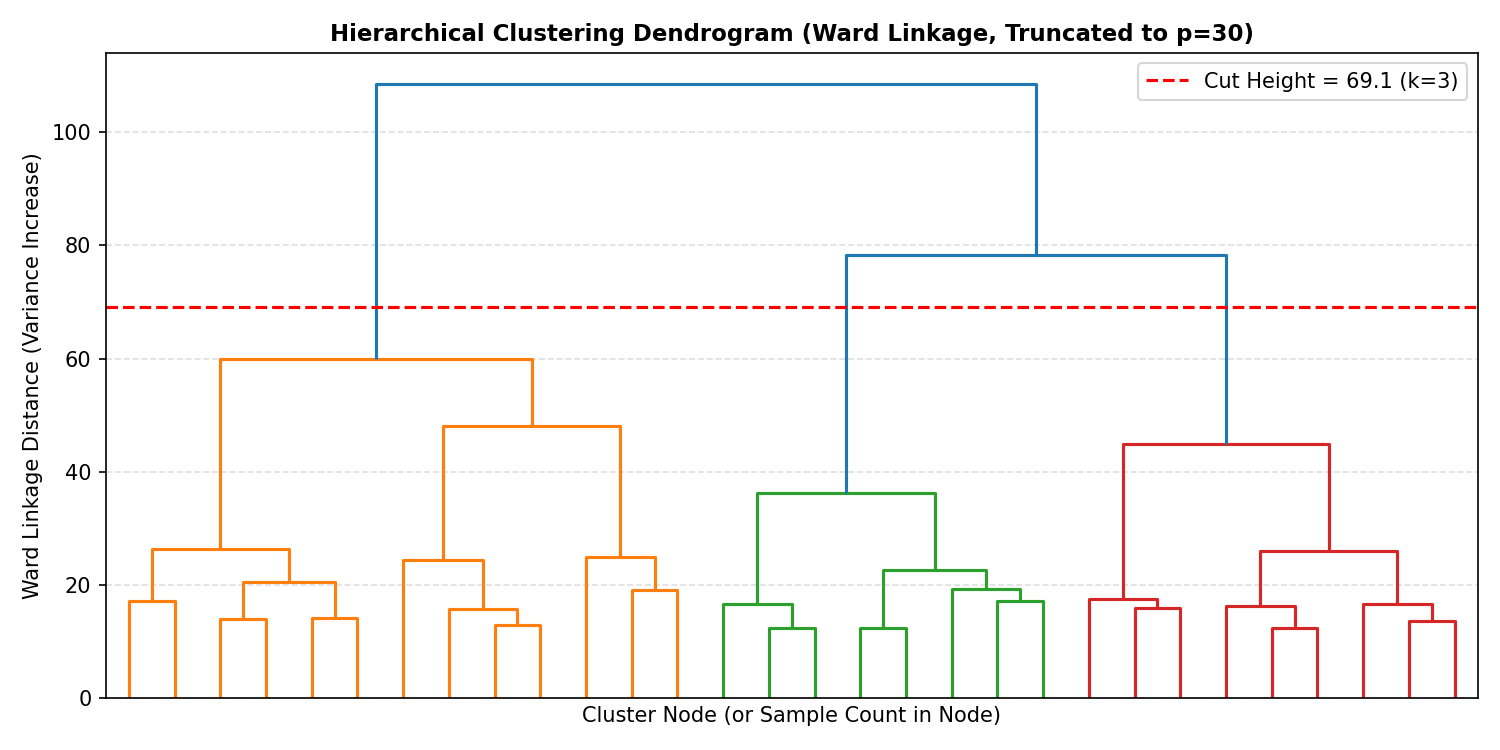

In [7]:
# Compute Ward linkage matrix
Z_ward = linkage(Z, method="ward")

# Calculate cut height that partitions into best_k_km clusters
# The linkage matrix has shape (N-1, 4). The last merge is at index -1 (1 cluster),
# index -2 creates 2 clusters, index -3 creates 3 clusters.
cut_height = float((Z_ward[-(best_k_km - 1), 2] + Z_ward[-best_k_km, 2]) / 2.0)

# Plot truncated dendrogram
plt.figure(figsize=(10, 5))
dendrogram(
    Z_ward,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    no_labels=True,
    color_threshold=cut_height
)
plt.axhline(cut_height, color="red", linestyle="--", linewidth=1.5, label=f"Cut Height = {cut_height:.1f} (k={best_k_km})")
plt.title(f"Hierarchical Clustering Dendrogram (Ward Linkage, Truncated to p=30)", fontsize=11, fontweight="bold")
plt.xlabel("Cluster Node (or Sample Count in Node)", fontsize=10)
plt.ylabel("Ward Linkage Distance (Variance Increase)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4, axis="y")
plt.legend(frameon=True)
plt.tight_layout()

plt.savefig("visualizations/25_dendrogram.png", dpi=150)
plt.show()

# Parameter Sweep across k = 2 to 10 for Ward Linkage
hc_sweep_rows = []
for k in range(2, 11):
    hc = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(Z)
    sil = silhouette_score(Z, hc.labels_)
    hc_sweep_rows.append({
        "k": k,
        "Silhouette": sil
    })

df_hc_sweep = pd.DataFrame(hc_sweep_rows)
best_k_hc = int(df_hc_sweep.loc[df_hc_sweep["Silhouette"].idxmax(), "k"])
print("Hierarchical Agglomerative Clustering (Ward) Parameter Sweep:")
print(df_hc_sweep.round(4).to_string(index=False))
print(f"\nOptimal Ward Hierarchical cluster count: best_k_hc = {best_k_hc} (Silhouette Score = {df_hc_sweep['Silhouette'].max():.4f})")

# Linkage Criterion Comparison at k = best_k_km
# Note: Single linkage is notorious for the 'chaining phenomenon'—merging neighboring points
# into one massive giant cluster accompanied by tiny isolated singleton clusters.
linkage_types = ["ward", "complete", "average", "single"]
linkage_comp_rows = []

for lt in linkage_types:
    hc_lt = AgglomerativeClustering(n_clusters=best_k_km, linkage=lt).fit(Z)
    sil_lt = silhouette_score(Z, hc_lt.labels_)
    sizes_lt = list(np.bincount(hc_lt.labels_))
    linkage_comp_rows.append({
        "Linkage": lt,
        "k": best_k_km,
        "Silhouette": sil_lt,
        "Cluster_Sizes": sizes_lt
    })

df_linkage_comp = pd.DataFrame(linkage_comp_rows)
print(f"\nLinkage Criterion Comparison at k = {best_k_km}:")
print(df_linkage_comp.round(4).to_string(index=False))

# Fit optimal Ward model at best_k_hc
hc_optimal = AgglomerativeClustering(n_clusters=best_k_hc, linkage="ward").fit(Z)
hc_labels = hc_optimal.labels_

ari_hc = adjusted_rand_score(age_group, hc_labels)
nmi_hc = normalized_mutual_info_score(age_group, hc_labels)
print(f"\nWard Model (k={best_k_hc}) Alignment with Ground-Truth Age Cohorts:")
print(f"  Adjusted Rand Index (ARI):             {ari_hc:.4f}")
print(f"  Normalized Mutual Information (NMI):    {nmi_hc:.4f}")

# Cross-Algorithm Agreement at k = best_k_km
hc_k_km = AgglomerativeClustering(n_clusters=best_k_km, linkage="ward").fit(Z)
agreement_ari = adjusted_rand_score(km_labels, hc_k_km.labels_)
print(f"\nCross-Algorithm Agreement (ARI between K-Means and Ward at k={best_k_km}): {agreement_ari:.4f}")


DBSCAN Parameter Sweep Summary (First 15 combinations):
 eps  min_samples  n_clusters  noise_pct  silhouette
 0.4            5          34    51.6678     -0.3749
 0.6            5           2    16.1441      0.1850
 0.8            5           2     5.8706      0.2229
 1.0            5           1     2.5350         NaN
 1.2            5           1     1.4009         NaN
 1.4            5           1     0.7672         NaN
 1.6            5           1     0.5003         NaN
 1.8            5           1     0.3669         NaN
 2.0            5           1     0.3002         NaN
 2.2            5           1     0.2001         NaN
 2.4            5           1     0.1668         NaN
 2.6            5           1     0.1001         NaN
 2.8            5           1     0.1001         NaN
 3.0            5           1     0.0667         NaN
 0.4           10          12    81.9880      0.0768

Qualifying DBSCAN Configurations (2 <= clusters <= 10, Noise <= 30%):
 eps  min_samples  n_clus

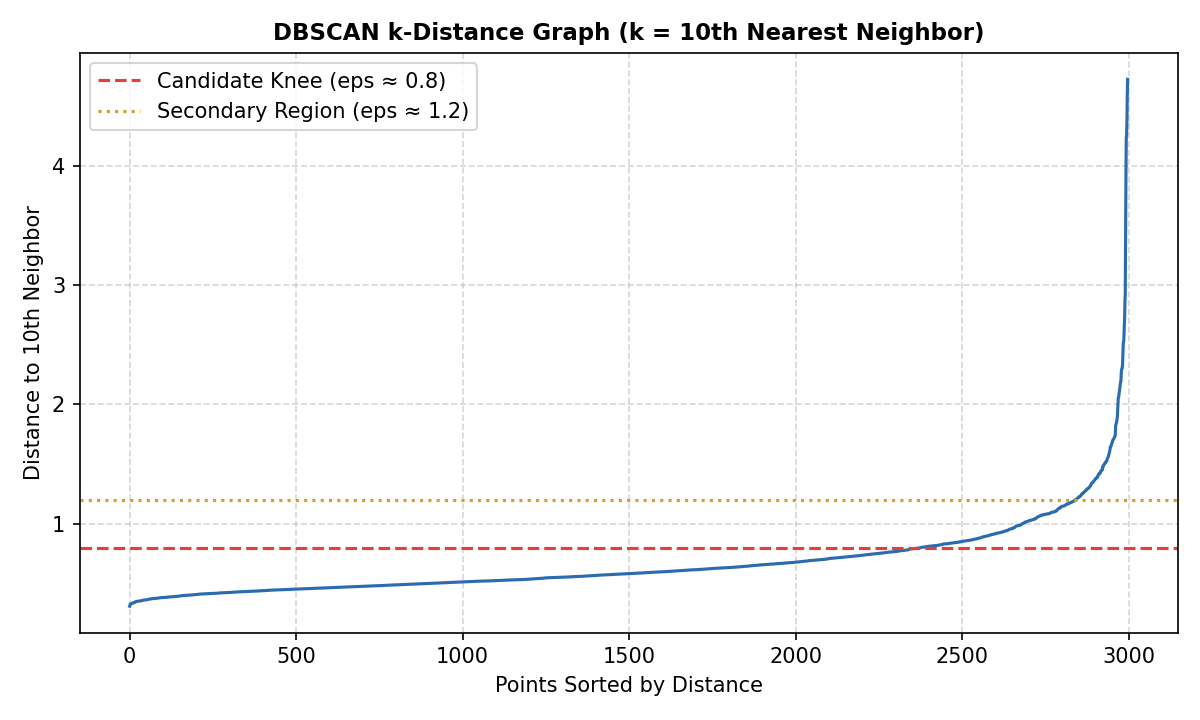

In [8]:
# 1. k-Distance Graph for min_samples = 10
nn = NearestNeighbors(n_neighbors=10).fit(Z)
distances, _ = nn.kneighbors(Z)
k_distances = np.sort(distances[:, 9])

plt.figure(figsize=(8, 4.8))
plt.plot(np.arange(len(k_distances)), k_distances, color="#2b6cb0", linewidth=1.5)
plt.axhline(0.8, color="#e53e3e", linestyle="--", label="Candidate Knee (eps ≈ 0.8)")
plt.axhline(1.2, color="#d69e2e", linestyle=":", label="Secondary Region (eps ≈ 1.2)")
plt.title("DBSCAN k-Distance Graph (k = 10th Nearest Neighbor)", fontsize=11, fontweight="bold")
plt.xlabel("Points Sorted by Distance", fontsize=10)
plt.ylabel("Distance to 10th Neighbor", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()

plt.savefig("visualizations/26_dbscan_kdistance.png", dpi=150)
plt.show()

# 2. Grid Search across eps and min_samples
# Note: DBSCAN silhouette is calculated exclusively on non-noise points, which can inflate
# scores artificially by omitting outliers.
eps_range = np.arange(0.4, 3.01, 0.2)
ms_range = [5, 10, 15]
dbscan_rows = []

for ms in ms_range:
    for eps in eps_range:
        db = DBSCAN(eps=eps, min_samples=ms).fit(Z)
        labels = db.labels_
        unique_c = set(labels) - {-1}
        n_clusters = len(unique_c)
        noise_pct = np.mean(labels == -1) * 100.0
        
        if n_clusters >= 2:
            non_noise_mask = (labels != -1)
            sil = silhouette_score(Z[non_noise_mask], labels[non_noise_mask])
        else:
            sil = np.nan
        
        dbscan_rows.append({
            "eps": round(eps, 2),
            "min_samples": ms,
            "n_clusters": n_clusters,
            "noise_pct": noise_pct,
            "silhouette": sil
        })

df_dbscan_sweep = pd.DataFrame(dbscan_rows)
print("DBSCAN Parameter Sweep Summary (First 15 combinations):")
print(df_dbscan_sweep.head(15).round(4).to_string(index=False))

# 3. Selection Rule: 2 <= n_clusters <= 10 and noise_pct <= 30%
qualifying_db = df_dbscan_sweep[
    (df_dbscan_sweep["n_clusters"] >= 2) &
    (df_dbscan_sweep["n_clusters"] <= 10) &
    (df_dbscan_sweep["noise_pct"] <= 30.0)
].dropna(subset=["silhouette"])

print("\nQualifying DBSCAN Configurations (2 <= clusters <= 10, Noise <= 30%):")
if len(qualifying_db) > 0:
    print(qualifying_db.round(4).to_string(index=False))
    best_db_row = qualifying_db.sort_values(by="silhouette", ascending=False).iloc[0]
    best_eps = float(best_db_row["eps"])
    best_ms = int(best_db_row["min_samples"])
    print(f"\nOptimal DBSCAN selected: eps = {best_eps}, min_samples = {best_ms} (Silhouette = {best_db_row['silhouette']:.4f})")
    
    # Fit optimal DBSCAN model
    db_optimal = DBSCAN(eps=best_eps, min_samples=best_ms).fit(Z)
    db_labels = db_optimal.labels_
    non_noise = (db_labels != -1)
    
    ari_db = adjusted_rand_score(age_group[non_noise], db_labels[non_noise])
    nmi_db = normalized_mutual_info_score(age_group[non_noise], db_labels[non_noise])
    
    cluster_counts = pd.Series(db_labels).value_counts().sort_index()
    print("\nDBSCAN Cluster Sizes (including -1 for noise):")
    for lbl, count in cluster_counts.items():
        name = "Noise" if lbl == -1 else f"Cluster {lbl}"
        print(f"  {name:10s}: {count:4d} instances ({count/len(Z)*100:5.2f}%)")
    
    print(f"\nDBSCAN Alignment with Ground-Truth Age Cohorts (Non-Noise Points Only):")
    print(f"  Adjusted Rand Index (ARI):             {ari_db:.4f}")
    print(f"  Normalized Mutual Information (NMI):    {nmi_db:.4f}")
else:
    print("DBSCAN found no usable cluster structure under the selection rule")
    db_labels = None
    ari_db = np.nan
    nmi_db = np.nan


Comprehensive Clustering Comparison Summary:
                   Method              Parameters  n_clusters  Silhouette  ARI_vs_age_group  NMI_vs_age_group  Noise_pct
                  K-Means          k=3, n_init=10           3      0.3095            0.0649            0.0720     0.0000
        Ward Hierarchical       k=2, linkage=ward           2      0.2616            0.0055            0.0098     0.0000
                   DBSCAN  eps=0.8, min_samples=5           2      0.2229           -0.0006            0.0003     5.8706
Random labels (reference) uniform discrete [0, 2]           3     -0.0044           -0.0000            0.0010     0.0000

Saved clustering comparison to: data/processed/ce2_clustering_results.csv



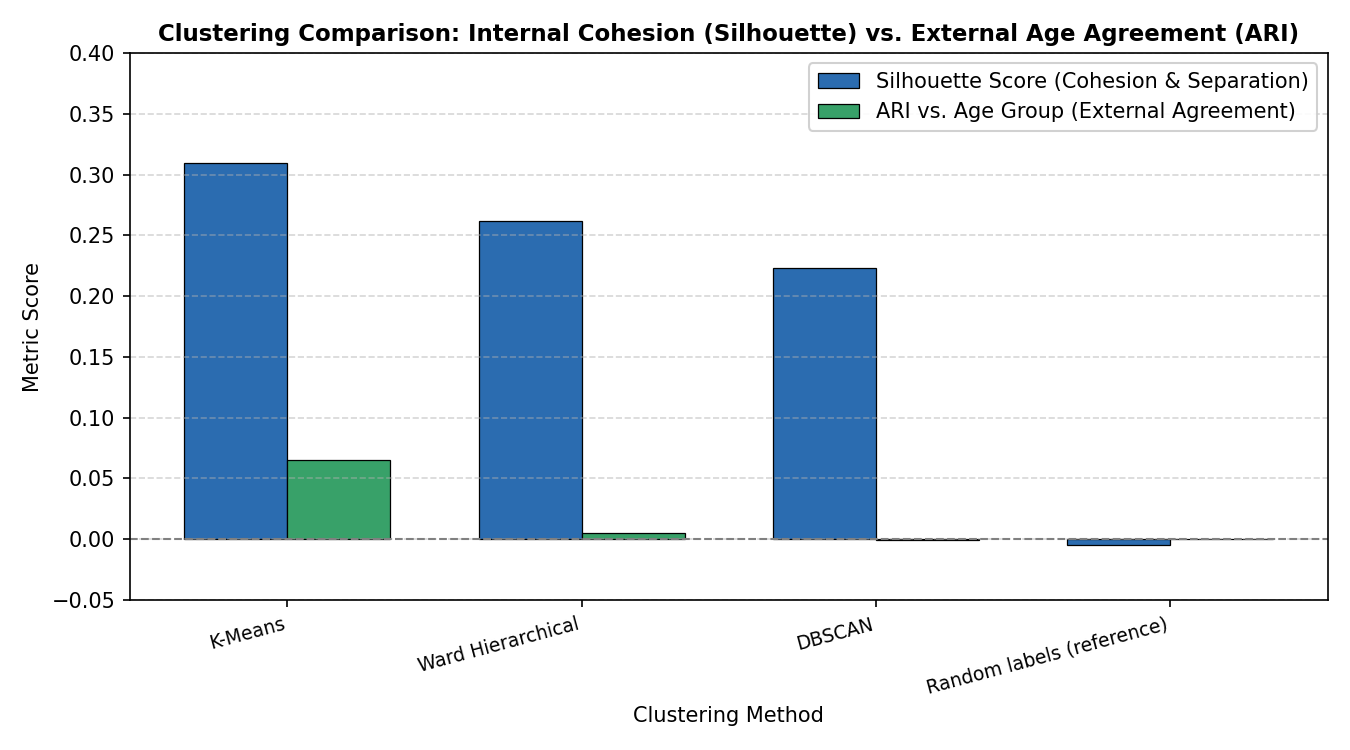

In [9]:
# Generate baseline null reference using random cluster assignments
rng = np.random.default_rng(42)
rand_labels = rng.integers(0, best_k_km, size=len(Z))
rand_sil = silhouette_score(Z, rand_labels)
rand_ari = adjusted_rand_score(age_group, rand_labels)
rand_nmi = normalized_mutual_info_score(age_group, rand_labels)

# Build comprehensive summary comparison table
comparison_records = [
    {
        "Method": "K-Means",
        "Parameters": f"k={best_k_km}, n_init=10",
        "n_clusters": best_k_km,
        "Silhouette": best_km_sil,
        "ARI_vs_age_group": ari_km,
        "NMI_vs_age_group": nmi_km,
        "Noise_pct": 0.0
    },
    {
        "Method": "Ward Hierarchical",
        "Parameters": f"k={best_k_hc}, linkage=ward",
        "n_clusters": best_k_hc,
        "Silhouette": df_hc_sweep.loc[df_hc_sweep['k'] == best_k_hc, 'Silhouette'].values[0],
        "ARI_vs_age_group": ari_hc,
        "NMI_vs_age_group": nmi_hc,
        "Noise_pct": 0.0
    }
]

if db_labels is not None:
    comparison_records.append({
        "Method": "DBSCAN",
        "Parameters": f"eps={best_eps}, min_samples={best_ms}",
        "n_clusters": int(best_db_row["n_clusters"]),
        "Silhouette": float(best_db_row["silhouette"]),
        "ARI_vs_age_group": ari_db,
        "NMI_vs_age_group": nmi_db,
        "Noise_pct": float(best_db_row["noise_pct"])
    })

comparison_records.append({
    "Method": "Random labels (reference)",
    "Parameters": f"uniform discrete [0, {best_k_km-1}]",
    "n_clusters": best_k_km,
    "Silhouette": rand_sil,
    "ARI_vs_age_group": rand_ari,
    "NMI_vs_age_group": rand_nmi,
    "Noise_pct": 0.0
})

df_clustering_summary = pd.DataFrame(comparison_records)
print("Comprehensive Clustering Comparison Summary:")
print(df_clustering_summary.round(4).to_string(index=False))

# Persist results to disk
df_clustering_summary.to_csv("data/processed/ce2_clustering_results.csv", index=False)
print("\nSaved clustering comparison to: data/processed/ce2_clustering_results.csv")

# Comparative Bar Chart: Silhouette Score and ARI per method
fig, ax = plt.subplots(figsize=(9, 5))
methods = df_clustering_summary["Method"]
x_pos = np.arange(len(methods))
bar_width = 0.35

bars_sil = ax.bar(x_pos - bar_width/2, df_clustering_summary["Silhouette"], width=bar_width, color="#2b6cb0", edgecolor="black", linewidth=0.6, label="Silhouette Score (Cohesion & Separation)")
bars_ari = ax.bar(x_pos + bar_width/2, df_clustering_summary["ARI_vs_age_group"], width=bar_width, color="#38a169", edgecolor="black", linewidth=0.6, label="ARI vs. Age Group (External Agreement)")

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Clustering Comparison: Internal Cohesion (Silhouette) vs. External Age Agreement (ARI)", fontsize=11, fontweight="bold")
ax.set_xlabel("Clustering Method", fontsize=10)
ax.set_ylabel("Metric Score", fontsize=10)
ax.set_xticks(x_pos)
ax.set_xticklabels(methods, rotation=15, ha="right", fontsize=9)
ax.set_ylim(-0.05, 0.40)
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
ax.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper right")
plt.tight_layout()

plt.savefig("visualizations/27_clustering_comparison.png", dpi=150)
plt.show()


### Observation

*(This section is reserved for user observations and qualitative synthesis regarding principal component loadings, morphological clustering structures, external age alignment, and comparative algorithm trade-offs.)*
